# **Preparing Dependancies**

In [1]:
!pip install -q diffusers transformers accelerate safetensors


In [2]:
import torch
import numpy as np
from PIL import Image, ImageDraw, ImageOps, ImageFilter, ImageChops
import matplotlib.pyplot as plt
from matplotlib import gridspec
import cv2
from skimage import segmentation
from diffusers import (
    StableDiffusionPipeline,
    StableDiffusionInpaintPipeline,
    EulerAncestralDiscreteScheduler,
    DPMSolverMultistepScheduler,
    DDIMScheduler,
    LMSDiscreteScheduler,
    StableDiffusionImg2ImgPipeline
)
from transformers import pipeline as hf_pipeline
import random
from tqdm.auto import tqdm
from google.colab import userdata
from huggingface_hub import login
import warnings
warnings.filterwarnings('ignore')
import logging
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)

device = "cuda" if torch.cuda.is_available() else "cpu"


Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


In [3]:
def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.Generator("cuda").manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [4]:
# @title hf login - hidden
hf_token = userdata.get("HF_TOKEN")
login(hf_token)

# **Kriteria 1: Melakukan Image Generation dari Teks (Text-to-Image)**

## **Load Base Pipeline Model**

In [5]:
model_id = "runwayml/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    safety_checker=None,
    requires_safety_checker=False
)
pipe = pipe.to(device)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


## **Generate Image**

In [6]:
PROMPT = "cartoon astronaut standing on mars surface, planet earth visible in space background"

NEGATIVE_PROMPT = "photorealistic, realistic, photograph, 3d render, messy, blurry, low quality, bad art, ugly, sketch, grainy, unfinished, chromatic aberration"

SEED = 222

In [7]:
def generate_simple_image(prompt, negative_prompt, seed):
  generator = torch.Generator("cuda").manual_seed(seed)
  result = pipe(
      prompt,
      negative_prompt,
      generator=generator
  )
  return result.images[0]

def generate_advanced_image(prompt, negative_prompt, guidance_scale, num_inference_steps, seed):
  generator = torch.Generator(device="cuda").manual_seed(seed)

  result = pipe(
    prompt,
    negative_prompt=negative_prompt,
    num_inference_steps=num_inference_steps,
    guidance_scale=guidance_scale,
    generator=generator
  )
  return result.images[0]


  0%|          | 0/50 [00:00<?, ?it/s]

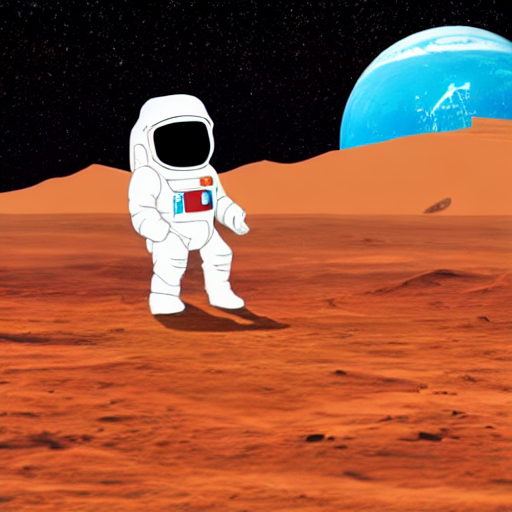

In [8]:
simple_image = generate_simple_image(PROMPT, NEGATIVE_PROMPT, SEED)

simple_image

In [9]:
simple_image.save("simple_image.png")

## **Generate Image with Hyperparameter Configuration**

  0%|          | 0/40 [00:00<?, ?it/s]

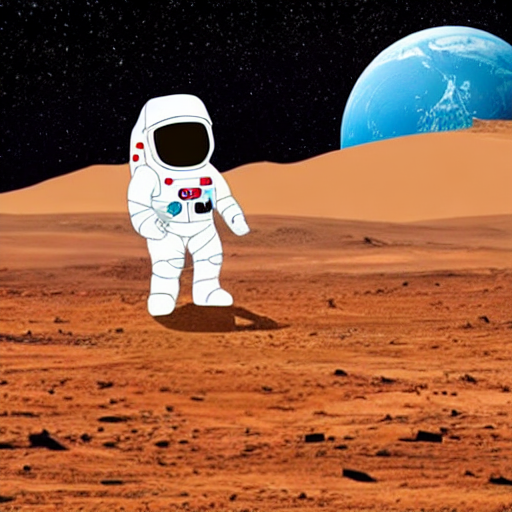

In [10]:
advanced_image = generate_advanced_image(
    PROMPT,
    NEGATIVE_PROMPT,
    7.5,
    40,
    SEED
)

advanced_image

In [11]:
advanced_image.save("advanced_image.png")

## **Guidance Scale Comparison**

In [12]:
guidance_scales = [7.5, 15.0]
scale_images = []

for scale in guidance_scales:
    print(f"Generating with guidance_scale={scale}")
    img = generate_advanced_image(
        prompt=PROMPT,
        negative_prompt=NEGATIVE_PROMPT,
        guidance_scale=scale,
        num_inference_steps=30,
        seed=SEED
    )
    scale_images.append(img)


Generating with guidance_scale=7.5


  0%|          | 0/30 [00:00<?, ?it/s]

Generating with guidance_scale=15.0


  0%|          | 0/30 [00:00<?, ?it/s]

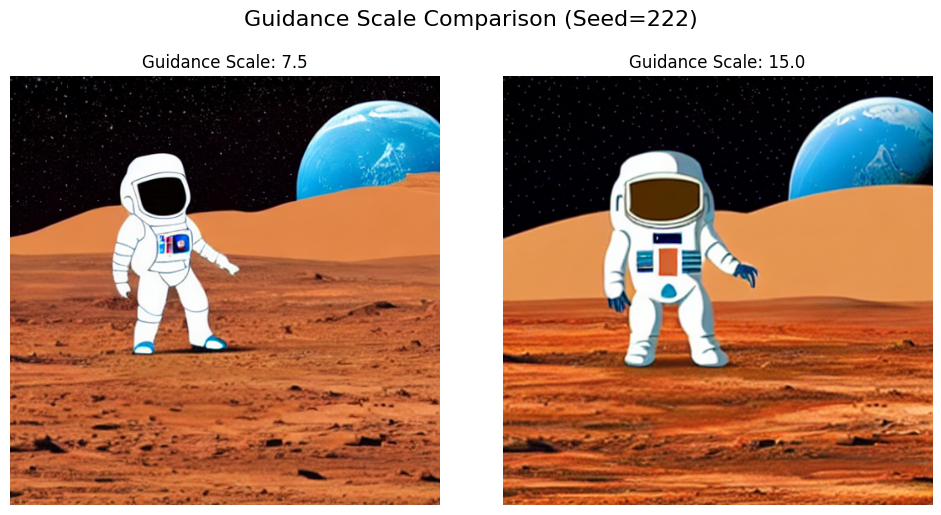

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes = axes.flat

for i, (scale, img) in enumerate(zip(guidance_scales, scale_images)):
    axes[i].imshow(img)
    axes[i].set_title(f"Guidance Scale: {scale}")
    axes[i].axis('off')

axes[-1].axis('off')

plt.suptitle("Guidance Scale Comparison (Seed=222)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

### **Guidance Scale Explanation:**

*   **Gambar dengan "Scale" Rendah:**   
*"Pada gambar dengan guidance scale rendah (7.5), hasil visual masih cukup sesuai dengan prompt yaitu menampilkan astronot di permukaan mirip Mars dengan latar planet dan langit berbintang. Namun detailnya cenderung lebih sederhana dan gaya ilustrasinya sedikit lebih longgar, sehingga memberi kesan variasi kreatif yang lebih bebas (misalnya pose dan proporsi yang agak santai). "*

*   **Gambar dengan "Scale" Tinggi:**   
*"Sementara itu, pada guidance scale tinggi (15.0), gambar terlihat lebih tajam, rapi, dan lebih “patuh” terhadap interpretasi umum dari prompt: bentuk astronot lebih tegas, elemen visual seperti pakaian dan latar tampak lebih terstruktur, serta komposisi keseluruhan lebih fokus dan konsisten. Perbedaannya menunjukkan bahwa scale rendah memberi fleksibilitas visual lebih besar, sedangkan scale tinggi meningkatkan presisi dan kedekatan terhadap deskripsi yang diinginkan."*

## **Inference Steps Comparison**

In [14]:
step_configs = [
    ("Low Steps (5)", 5),
    # ("Medium Steps (15)", 15),
    ("High Steps (30)", 30),
    # ("Very High Steps (50)", 50)
]

step_images = []

for name, steps in step_configs:
    print(f"Generating with {steps} inference steps")
    img = generate_advanced_image(
        prompt=PROMPT,
        negative_prompt=NEGATIVE_PROMPT,
        guidance_scale=7.5,
        num_inference_steps=steps,
        seed=SEED
    )
    step_images.append((name, img))


Generating with 5 inference steps


  0%|          | 0/5 [00:00<?, ?it/s]

Generating with 30 inference steps


  0%|          | 0/30 [00:00<?, ?it/s]

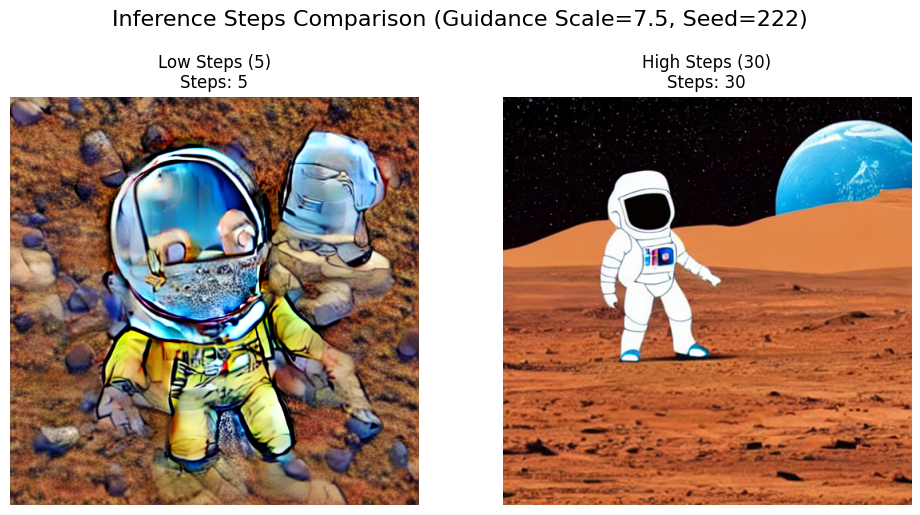

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes = axes.flat

for i, (name, img) in enumerate(step_images):
    axes[i].imshow(img)
    axes[i].set_title(f"{name}\nSteps: {step_configs[i][1]}")
    axes[i].axis('off')

plt.suptitle("Inference Steps Comparison (Guidance Scale=7.5, Seed=222)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

### **Inference Step Explanation:**

*   **Gambar dengan "Step" Rendah:**  
*"Pada gambar dengan inference step rendah (5), hasil visual terlihat kurang stabil dengan detail yang tidak konsisten. Tekstur tampak kasar dan cenderung mengandung noise atau artefak, terutama pada bentuk astronot dan latar yang terlihat “melebur” atau terdistorsi. Ketajaman objek rendah, dan beberapa elemen sulit dikenali dengan jelas, menunjukkan proses generasi yang belum sempat menyempurnakan struktur gambar secara optimal."*
*   **Gambar dengan "Step" Tinggi:**  
*"Sebaliknya, pada gambar dengan inference step tinggi (30), kualitas visual meningkat signifikan. Detail objek lebih jelas dan tegas, bentuk astronot serta elemen latar terlihat rapi dan mudah dikenali. Tekstur menjadi lebih halus, noise berkurang drastis, dan keseluruhan komposisi tampak lebih stabil serta konsisten. Hal ini menunjukkan bahwa langkah inferensi yang lebih banyak memberi waktu bagi model untuk menyempurnakan gambar sehingga hasilnya lebih bersih dan mendekati representasi yang diinginkan."*

## **Batch Inference from One Prompt**

  0%|          | 0/50 [00:00<?, ?it/s]

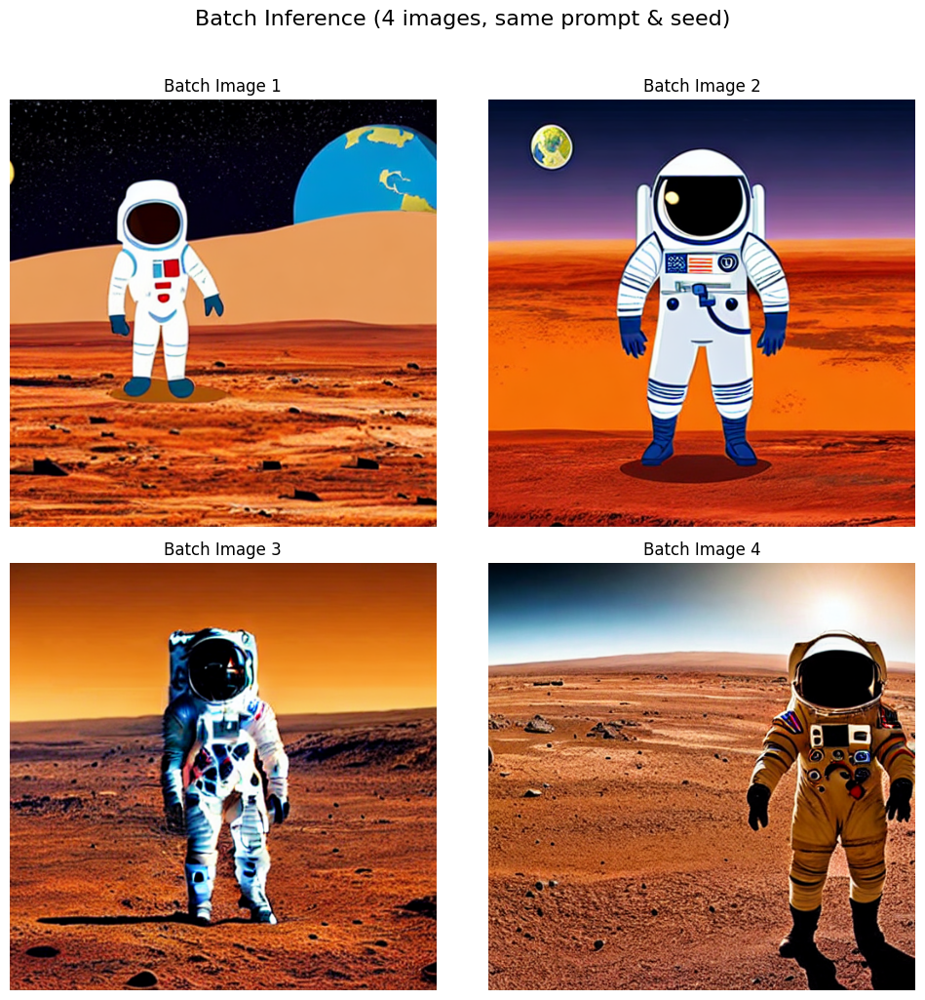

In [16]:
def generate_batch_images(prompt, negative_prompt, num_images, seed):
    """Generate multiple images in batch"""
    set_seed(seed)

    results = pipe(
        [prompt] * num_images,
        negative_prompt=[negative_prompt] * num_images,
        num_inference_steps=50,
        guidance_scale=12,
        height=512,
        width=512
    )

    return results.images

batch_images = generate_batch_images(
    prompt=PROMPT,
    negative_prompt=NEGATIVE_PROMPT,
    num_images=4,
    seed=SEED
)

# Display 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes = axes.flat

for i, img in enumerate(batch_images):
    axes[i].imshow(img)
    axes[i].set_title(f"Batch Image {i+1}")
    axes[i].axis('off')

plt.suptitle("Batch Inference (4 images, same prompt & seed)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()


Generating batch with different seeds...


  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

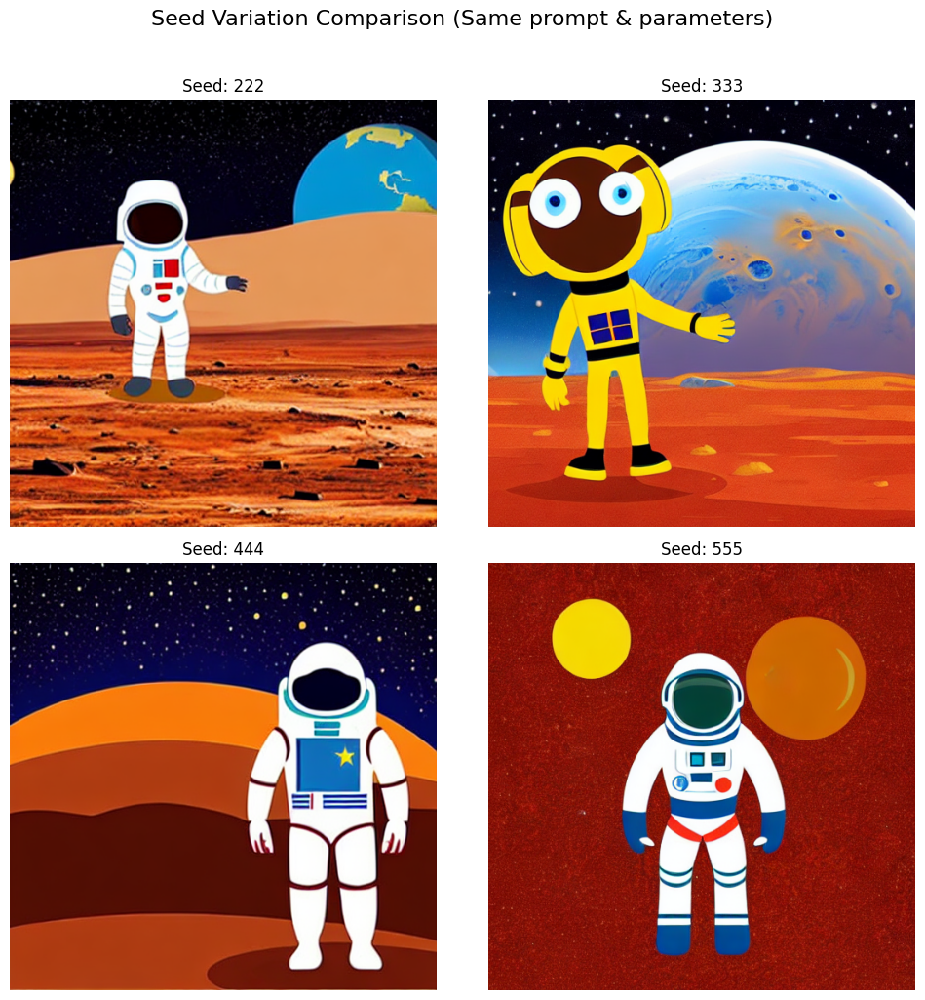

In [17]:
print("Generating batch with different seeds...")
variation_images = []
seeds = [222, 333, 444, 555]

for seed in seeds:
    set_seed(seed)
    img = generate_advanced_image(
        prompt=PROMPT,
        negative_prompt=NEGATIVE_PROMPT,
        num_inference_steps=50,
        guidance_scale=12,
        seed=seed
    )
    variation_images.append((f"Seed: {seed}", img))

# Display seed variations
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes = axes.flat

for i, (title, img) in enumerate(variation_images):
    axes[i].imshow(img)
    axes[i].set_title(title)
    axes[i].axis('off')

plt.suptitle("Seed Variation Comparison (Same prompt & parameters)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()


## **Load Scheduler**


Testing Euler A scheduler...
Scheduler changed to: Euler A


  0%|          | 0/50 [00:00<?, ?it/s]


Testing DPM++ scheduler...
Scheduler changed to: DPM++


  0%|          | 0/50 [00:00<?, ?it/s]


Testing DDIM scheduler...
Scheduler changed to: DDIM


  0%|          | 0/50 [00:00<?, ?it/s]

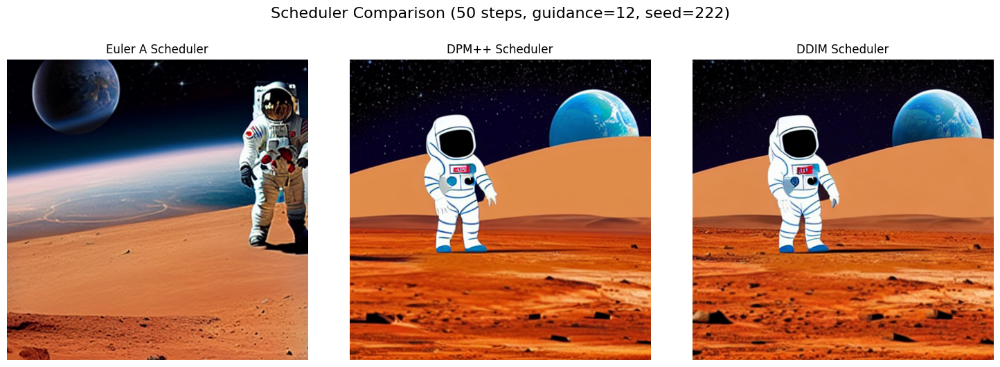

In [18]:
def load_scheduler(pipe, scheduler_name):
    """Switch scheduler without reloading the model"""

    scheduler_config = pipe.scheduler.config

    if scheduler_name == "Euler A":
        new_scheduler = EulerAncestralDiscreteScheduler.from_config(scheduler_config)
    elif scheduler_name == "DPM++":
        new_scheduler = DPMSolverMultistepScheduler.from_config(scheduler_config)
    elif scheduler_name == "DDIM":
        new_scheduler = DDIMScheduler.from_config(scheduler_config)
    elif scheduler_name == "LMS":
        new_scheduler = LMSDiscreteScheduler.from_config(scheduler_config)
    else:
        raise ValueError(f"Unknown scheduler: {scheduler_name}")

    pipe.scheduler = new_scheduler
    print(f"Scheduler changed to: {scheduler_name}")
    return pipe

scheduler_names = ["Euler A", "DPM++", "DDIM"]
scheduler_images = []

for sched_name in scheduler_names:
    print(f"\nTesting {sched_name} scheduler...")

    test_pipe = pipe
    test_pipe = load_scheduler(test_pipe, sched_name)

    set_seed(SEED)

    result = test_pipe(
        PROMPT,
        negative_prompt=NEGATIVE_PROMPT,
        num_inference_steps=50,
        guidance_scale=12,
        height=512,
        width=512
    )

    scheduler_images.append((sched_name, result.images[0]))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, (name, img) in enumerate(scheduler_images):
    axes[i].imshow(img)
    axes[i].set_title(f"{name} Scheduler")
    axes[i].axis('off')

plt.suptitle("Scheduler Comparison (50 steps, guidance=12, seed=222)", fontsize=16, y=1.05)
plt.tight_layout()
plt.show()

### **Scheduler Comparation:**

*   **Gambar dengan "Euler A Scheduler":**  
*"Gambar menampilkan astronot dengan pendekatan yang lebih realistis, terutama pada pencahayaan dan tekstur lingkungan. Permukaan tanah dan langit memiliki gradasi warna yang kuat serta kontras tinggi, memberikan kesan dramatis. Namun, terdapat ketidakkonsistenan visual antara astronot dan latar—astronot tampak lebih seperti foto nyata, sementara elemen lain sedikit berbeda gaya. Detail tertentu terlihat tajam, tetapi sebagian area tampak kasar atau kurang halus, sehingga keseluruhan gambar terasa kurang homogen."*
*   **Gambar dengan "DPM++ Scheduler":**  
*"Gambar menghasilkan tampilan yang paling seimbang dan konsisten. Astronot dan lingkungan memiliki gaya ilustratif yang seragam, dengan garis yang jelas dan bentuk yang stabil. Warna terlihat cerah namun terkontrol, dengan transisi yang halus antar elemen. Detail pada objek utama dan latar cukup tajam tanpa menimbulkan noise atau artefak yang mengganggu. Komposisi terlihat rapi, dengan pemisahan objek dan latar yang jelas, sehingga keseluruhan gambar tampak bersih dan terstruktur."*
*   **Gambar dengan "DDIM Scheduler":**  
*"Gambar menunjukkan hasil yang halus dan stabil secara visual. Astronot dan latar tetap konsisten dalam gaya ilustratif, namun tingkat ketajaman dan detail sedikit lebih rendah dibandingkan DPM++. Warna tampak lebih lembut dengan kontras yang tidak terlalu kuat. Tekstur permukaan terlihat lebih sederhana, dan tidak banyak detail kecil yang menonjol. Meskipun demikian, noise sangat minim dan bentuk objek tetap, menghasilkan gambar yang rapi namun cenderung kurang kaya detail dan variasi visual."*

# **Kriteria 2: Menyempurnakan Gambar Melalui Image-to-Image**

## **Base + Refiner Image Generation**

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion_img2img.StableDiffusionImg2ImgPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or aud

Testing Two-Stage Generation (Base + Refiner)...
Stage 1: Base generation (denoising_end=0.8)


  0%|          | 0/50 [00:00<?, ?it/s]

Stage 2: Refinement (denoising_start=0.8)


  0%|          | 0/40 [00:00<?, ?it/s]

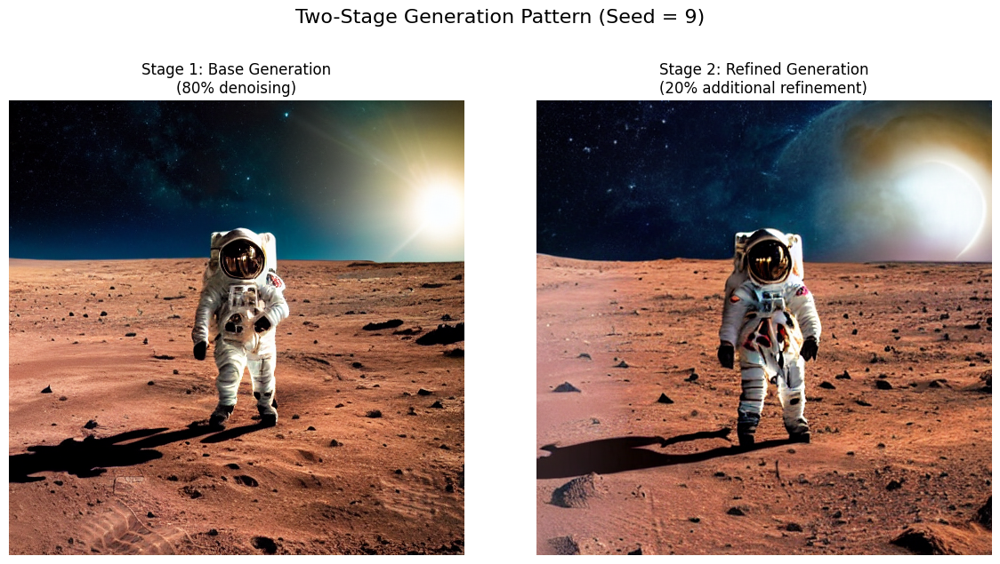

In [19]:
refiner_pipe = StableDiffusionImg2ImgPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    safety_checker=None
)
refiner_pipe = refiner_pipe.to(device)

def two_stage_generation(prompt, negative_prompt, seed):
    """Implement refiner pattern: base generation + refinement"""

    print("Stage 1: Base generation (denoising_end=0.8)")

    set_seed(seed)
    base_result = pipe(
        prompt,
        negative_prompt=negative_prompt,
        num_inference_steps=50,
        guidance_scale=7.5,
        height=512,
        width=512,
        output_type="latent",
        denoising_end=0.8
    )

    # Get latent
    latents = base_result.images

    print("Stage 2: Refinement (denoising_start=0.8)")

    # Convert latent to image for img2img input
    with torch.no_grad():
        intermediate_image = pipe.decode_latents(latents)
        intermediate_image = pipe.numpy_to_pil(intermediate_image)[0]

    # Refine with img2img
    refined_result = refiner_pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        image=intermediate_image,
        # strength=0.3,
        num_inference_steps=50,
        guidance_scale=7.5,
        denoising_start=0.8
    )

    return intermediate_image, refined_result.images[0]


print("Testing Two-Stage Generation (Base + Refiner)...")
intermediate_img, refined_img = two_stage_generation(
    prompt=PROMPT,
    negative_prompt=NEGATIVE_PROMPT,
    seed=9
)

# Display
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(intermediate_img)
axes[0].set_title("Stage 1: Base Generation\n(80% denoising)")
axes[0].axis('off')

axes[1].imshow(refined_img)
axes[1].set_title("Stage 2: Refined Generation\n(20% additional refinement)")
axes[1].axis('off')

plt.suptitle("Two-Stage Generation Pattern (Seed = 9)", fontsize=16, y=1.05)
plt.tight_layout()
plt.show()

Testing Two-Stage Generation (Base + Refiner)...
Stage 1: Base generation (denoising_end=0.8)


  0%|          | 0/50 [00:00<?, ?it/s]

Stage 2: Refinement (denoising_start=0.8)


  0%|          | 0/40 [00:00<?, ?it/s]

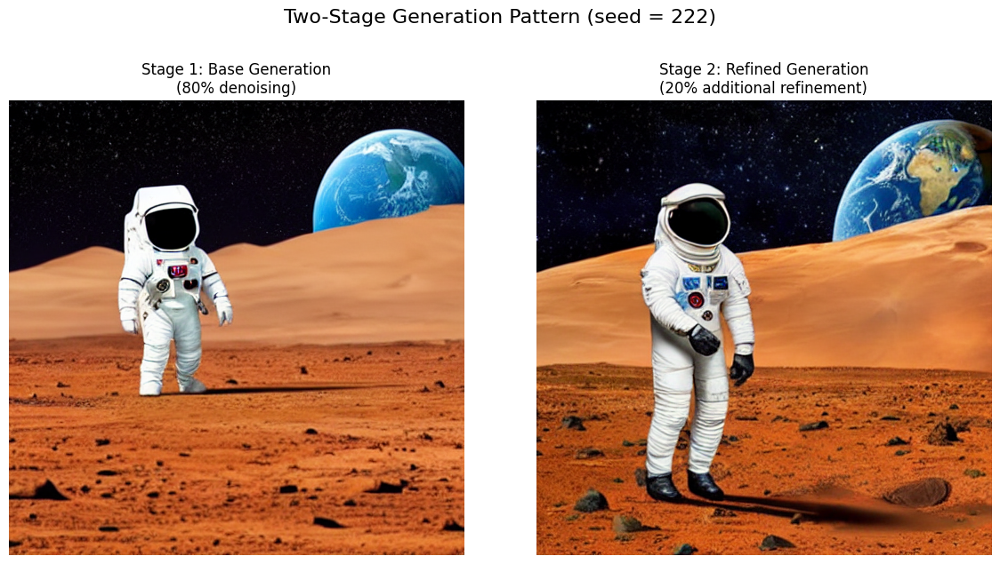

In [20]:
print("Testing Two-Stage Generation (Base + Refiner)...")
intermediate_img, refined_img = two_stage_generation(
    prompt=PROMPT,
    negative_prompt=NEGATIVE_PROMPT,
    seed=222
)

# Display
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(intermediate_img)
axes[0].set_title("Stage 1: Base Generation\n(80% denoising)")
axes[0].axis('off')

axes[1].imshow(refined_img)
axes[1].set_title("Stage 2: Refined Generation\n(20% additional refinement)")
axes[1].axis('off')

plt.suptitle("Two-Stage Generation Pattern (seed = 222)", fontsize=16, y=1.05)
plt.tight_layout()
plt.show()

## **Inpainting**

### **Load Model Inpainting**

In [21]:
model_id = "runwayml/stable-diffusion-inpainting"
pipe_inpaint = StableDiffusionInpaintPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    safety_checker=None
)
pipe_inpaint = pipe_inpaint.to(device)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--run

### **Manual Masking**

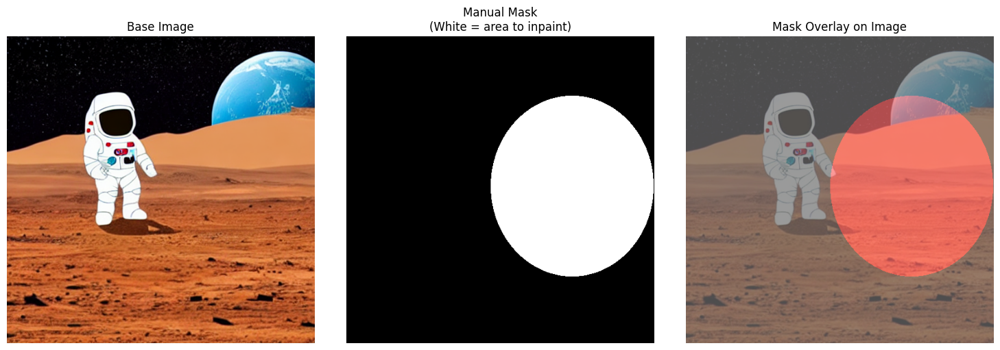

In [22]:
def create_manual_mask(image_size=512):
    """
    Mask the ground area next to the astronaut.
    """
    mask = Image.new("L", (image_size, image_size), 0)
    draw = ImageDraw.Draw(mask)
    # draw.rectangle([240, 150, 510, 400], fill=255)
    draw.ellipse([240, 100, 510, 400], fill=255)

    return mask

manual_mask = create_manual_mask()

# Display base image with mask overlay
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(advanced_image)
axes[0].set_title("Base Image")
axes[0].axis('off')

axes[1].imshow(manual_mask, cmap='gray')
axes[1].set_title("Manual Mask\n(White = area to inpaint)")
axes[1].axis('off')

# Create overlay
overlay = advanced_image.copy()
overlay.putalpha(128)
mask_overlay = manual_mask.convert("RGBA")

# Composite
result_overlay = Image.alpha_composite(overlay.convert("RGBA"), ImageChops.multiply(mask_overlay, Image.new("RGBA", manual_mask.size, (255, 0, 0, 100))))

axes[2].imshow(result_overlay)
axes[2].set_title("Mask Overlay on Image")
axes[2].axis('off')

plt.tight_layout()
plt.show()

### **Generate**

In [23]:
INPAINT_PROMPT = (
    "broken satellite lander on the ground, "
    "multiple damaged solar panels attached to the probe, "
)

NEGATIVE_INPROMPT = (
    "single solar panel, standalone panel, "
    "capsule, fuel tank, rocket stage, cylinder"
)

In [24]:
def inpaint_engine(image, mask, prompt, negative_prompt):
    generator = torch.Generator("cuda").manual_seed(9)

    result = pipe_inpaint(
        prompt=prompt,
        negative_prompt=negative_prompt,
        image=image,
        mask_image=mask,
        num_inference_steps=75,
        guidance_scale=6.5,
        strength=1.0,
        generator=generator
    )

    return result.images[0]

  0%|          | 0/75 [00:00<?, ?it/s]

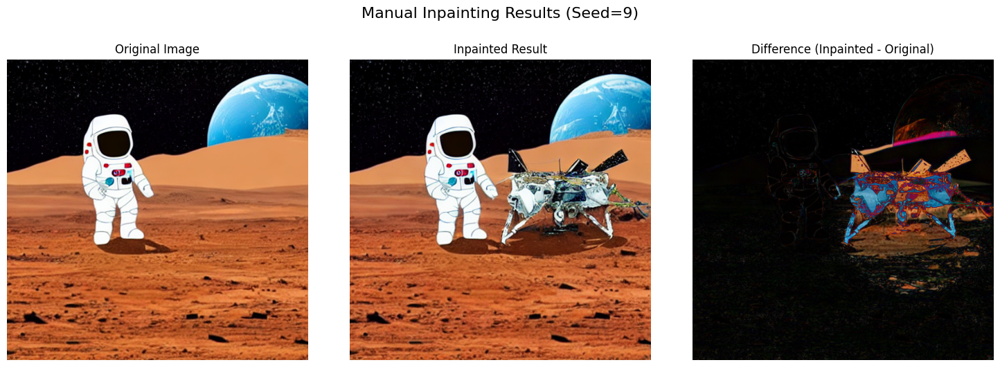

In [25]:
manual_inpaint_result = inpaint_engine(
    advanced_image,
    manual_mask,
    INPAINT_PROMPT,
    NEGATIVE_INPROMPT
)

# Display results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(advanced_image)
axes[0].set_title("Original Image")
axes[0].axis('off')

axes[1].imshow(manual_inpaint_result)
axes[1].set_title(f"Inpainted Result")
axes[1].axis('off')

# Show difference
diff = np.array(manual_inpaint_result).astype(float) - np.array(advanced_image).astype(float)
diff = np.abs(diff).astype(np.uint8)

axes[2].imshow(diff)
axes[2].set_title("Difference (Inpainted - Original)")
axes[2].axis('off')

plt.suptitle("Manual Inpainting Results (Seed=9)", fontsize=16, y=1.05)
plt.tight_layout()
plt.show()

In [26]:
manual_inpaint_result.save("manual_inpaint_result.png")

## **Inpainting Menggunakan Automasking**

### **load Model Segmentation Untuk Masking**

In [27]:
segmenter = hf_pipeline(
    "image-segmentation",
    model="nvidia/segformer-b5-finetuned-ade-640-640"
)

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/339M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/1172 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/339M [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

The image processor of type `SegformerImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


### **Masking with Segmentation Model**

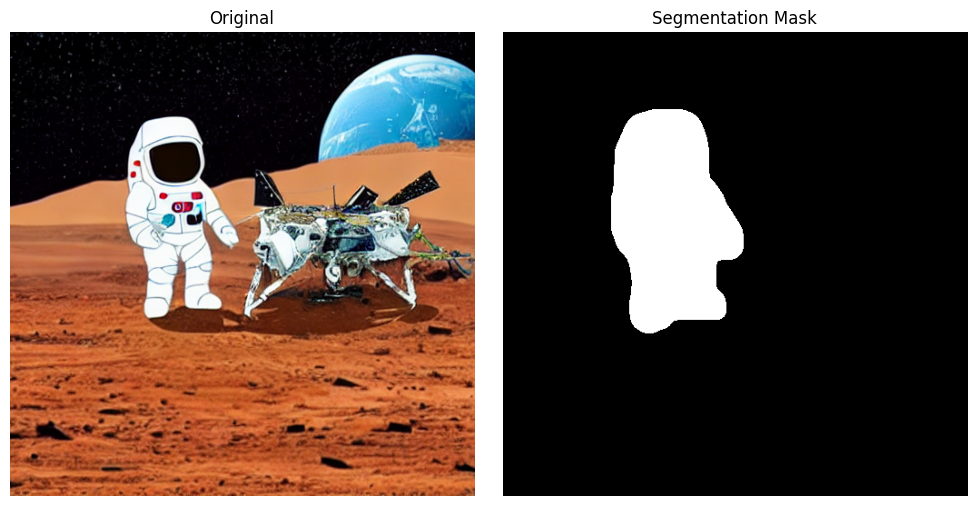

In [28]:
image = manual_inpaint_result.convert("RGB")
w, h = image.size

segments = segmenter(image)

mask_total = np.zeros((h, w), dtype=np.uint8)

for seg in segments:
    label = seg["label"].lower()

    # Catch person
    if any(x in label for x in ["person", "man", "woman"]):
        mask = np.array(seg["mask"]).astype(np.uint8)

        mask = cv2.resize(mask, (w, h), interpolation=cv2.INTER_NEAREST)

        mask_total = np.maximum(mask_total, mask)

num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask_total, connectivity=8)

if num_labels > 1:
    largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    mask_total = (labels == largest_label).astype(np.uint8)

kernel = np.ones((10, 10), np.uint8)

mask_total = cv2.morphologyEx(mask_total, cv2.MORPH_CLOSE, kernel)
mask_total = cv2.dilate(mask_total, kernel, iterations=2)
mask_total = cv2.erode(mask_total, kernel, iterations=1)

mask_total = cv2.GaussianBlur(mask_total.astype(np.float32), (21,21), 0)
mask_total = (mask_total > 0.1).astype(np.uint8)

mask_image = Image.fromarray(mask_total * 255)
mask_image.save("debug_mask.png")

fig, axes = plt.subplots(1, 2, figsize=(10,5))

axes[0].imshow(image)
axes[0].set_title("Original")
axes[0].axis('off')

axes[1].imshow(mask_image, cmap='gray')
axes[1].set_title("Segmentation Mask")
axes[1].axis('off')

plt.tight_layout()
plt.show()


### **Generate**

  0%|          | 0/30 [00:00<?, ?it/s]

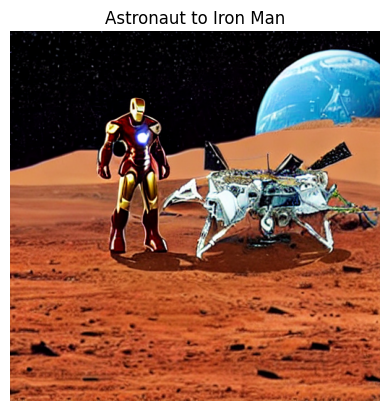

In [29]:
prompt = """
marvel iron man, red and gold armored suit,
futuristic armor, glowing arc reactor,
cinematic lighting, ultra detailed,
"""

negative_prompt = """
astronaut, white suit, cartoon, blurry, low quality
"""

result = pipe_inpaint(
    prompt=prompt,
    # negative_prompt=negative_prompt,
    image=image.resize((512,512)),
    mask_image=mask_image.resize((512,512)),
    guidance_scale=30,
    strength=1.0,
    num_inference_steps=30,
    generator=torch.Generator("cuda").manual_seed(222)
).images[0]

result.save("output.png")

plt.imshow(result)
plt.title("Astronaut to Iron Man")
plt.axis('off')
plt.show()

## **Outpainting**

### **Prepare the Canvas**

In [30]:
def prepare_outpainting(
    image: Image.Image,
    expand_px: int = 256,
    direction: str = "right",
    fill_color=(0, 0, 0)
):
    old_w, old_h = image.size

    if direction == "right":
        new_w, new_h = old_w + expand_px, old_h
        paste_pos = (0, 0)
        mask_paste_pos = (0, 0)

    elif direction == "left":
        new_w, new_h = old_w + expand_px, old_h
        paste_pos = (expand_px, 0)
        mask_paste_pos = (expand_px, 0)

    elif direction == "bottom":
        new_w, new_h = old_w, old_h + expand_px
        paste_pos = (0, 0)
        mask_paste_pos = (0, 0)

    elif direction == "top":
        new_w, new_h = old_w, old_h + expand_px
        paste_pos = (0, expand_px)
        mask_paste_pos = (0, expand_px)

    else:
        raise ValueError("direction harus right/left/top/bottom")

    outpaint_image = Image.new("RGB", (new_w, new_h), fill_color)
    outpaint_image.paste(image, paste_pos)

    outpaint_mask = Image.new("L", (new_w, new_h), 255)

    original_area_mask = Image.new("L", image.size, 0)
    outpaint_mask.paste(original_area_mask, mask_paste_pos)

    outpaint_mask = outpaint_mask.point(lambda p: 255 if p > 0 else 0)

    return outpaint_image, outpaint_mask


outpaint_image, outpaint_mask = prepare_outpainting(
    image=manual_inpaint_result,
    expand_px=256,
    direction="right"
)

def fix_size(img):
    w, h = img.size
    return img.resize(((w // 64) * 64, (h // 64) * 64))

outpaint_image = fix_size(outpaint_image)
outpaint_mask = fix_size(outpaint_mask)

w, h = outpaint_image.size
print(f"Final size: {w} x {h}")

Final size: 768 x 512


### **Generate**

Expanding image...


  0%|          | 0/50 [00:00<?, ?it/s]

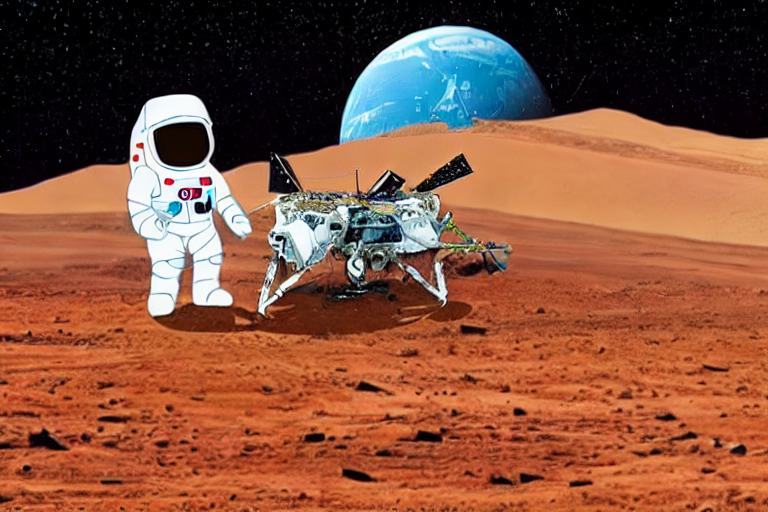

In [31]:
prompt_outpaint = """
ultra wide panoramic view, horizontal expansion to the right,
seamless continuation of mars terrain,
flat ground, consistent horizon,
empty red mars desert, detailed texture, space sky with stars
"""

negative_prompt = """
vertical objects, buildings, towers,
distorted perspective, warped horizon,
floating terrain, blurry, low quality
"""

generator = torch.Generator("cuda").manual_seed(222)

print("Expanding image...")

outpainting_result = pipe_inpaint(
    prompt=prompt_outpaint,
    negative_prompt=negative_prompt,
    image=outpaint_image,
    mask_image=outpaint_mask,
    guidance_scale=11,
    num_inference_steps=50,
    strength=1.0,
    width=w,
    height=h,
    generator=generator
).images[0]

outpainting_result

In [32]:
outpainting_result.save("outpainting_result.png")

## **Outpainting Zoom Out**

### **Prepare Canvas for Zoom Out**

In [33]:
def prepare_outpainting(image, expand_pixels=128, feather=10):
    old_w, old_h = image.size

    new_w = old_w + 2 * expand_pixels
    new_h = old_h + 2 * expand_pixels

    # canvas
    canvas = Image.new("RGB", (new_w, new_h), (10, 15, 30))
    canvas.paste(image, (expand_pixels, expand_pixels))

    mask = Image.new("L", (new_w, new_h), 255)

    # old area = black
    inner = Image.new("L", (old_w, old_h), 0)
    mask.paste(inner, (expand_pixels, expand_pixels))

    if feather > 0:
        mask = mask.filter(ImageFilter.GaussianBlur(feather))

    return canvas, mask


def fix_size(img):
    w, h = img.size
    return img.resize(((w // 64) * 64, (h // 64) * 64))


def zoom_out_generation(image, steps=1, expand_per_step=128):
    current_image = image
    results = [current_image]

    for step in range(steps):
        print(f"\nZoom-out step {step+1}/{steps}")

        canvas, mask = prepare_outpainting(
            current_image,
            expand_pixels=expand_per_step,
            feather=8
        )

        canvas = fix_size(canvas)
        mask = fix_size(mask)

        w, h = canvas.size

        zoom_prompt = "wide shot view, empty red mars surface, endless flat ground, dark black deep space sky, stars, highly detailed"

        negative = """iron man, alien, text, line, vertical objects, towers, pillars, architecture, buildings,
                  photorealistic, realistic, photograph, 3d render,
                  messy, blurry, low quality, bad art, ugly, sketch, grainy, unfinished, chromatic aberration"""

        generator = torch.Generator("cuda").manual_seed(100+step)

        result = pipe_inpaint(
            prompt=zoom_prompt,
            negative_prompt=negative,
            image=canvas,
            mask_image=mask,
            strength=1.0,
            guidance_scale=10,
            num_inference_steps=45,
            width=w,
            height=h,
            generator=generator
        ).images[0]

        current_image = result
        results.append(result)

    return results


### **Generate**

Token indices sequence length is longer than the specified maximum sequence length for this model (87 > 77). Running this sequence through the model will result in indexing errors


Starting zoom-out outpainting...

Zoom-out step 1/1


  0%|          | 0/45 [00:00<?, ?it/s]

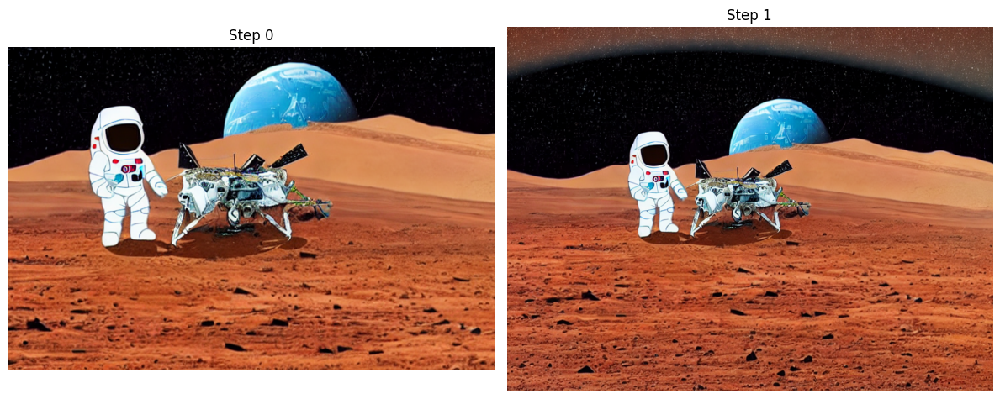

In [34]:
print("Starting zoom-out outpainting...")

zoom_results = zoom_out_generation(
    outpainting_result,
    steps=1,
    expand_per_step=128
)

fig, axes = plt.subplots(1, len(zoom_results), figsize=(6 * len(zoom_results), 6))

if len(zoom_results) == 1:
    axes = [axes]

for i, img in enumerate(zoom_results):
    axes[i].imshow(img)
    axes[i].set_title(f"Step {i}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()


In [35]:
!pip freeze>requirements.txt